# 04. Segment Specific Models and the Core Comparison

Goal: train a separate XGBoost model inside each segment, then compare it against the unified baseline.

This notebook answers RQ2, which asks whether segment specific classifiers outperform a unified model.

Two comparisons are made:

1. Aggregate comparison over the whole test set
2. Like for like comparison inside each segment, where the unified model is scored on exactly the same customers as the segment model

The second comparison matters. Segments differ in churn prevalence, and F1 rises as the positive class becomes more balanced, so a segment score cannot be compared against the unified model overall score.

Outputs:

* ../results/tables/comparison_unified_vs_segment.csv
* ../results/tables/like_for_like_comparison.csv
* ../results/figures/comparison.png


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings, joblib
warnings.filterwarnings('ignore')

from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from imblearn.over_sampling import SMOTE
import xgboost as xgb

SEED = 42
np.random.seed(SEED)

# Reuse the exact same split as notebook 03
data = joblib.load('../data/processed/train_test.pkl')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
seg_train, seg_test = data['seg_train'], data['seg_test']
print('Loaded the shared train and test split')

Loaded the shared train and test split


## 1. Train the unified baseline on the shared split

The same model as in notebook 03, retrained here so that its per customer predictions are available for the like for like comparison in step 4.

In [2]:
X_train_sm, y_train_sm = SMOTE(random_state=SEED).fit_resample(X_train, y_train)

unified_model = xgb.XGBClassifier(n_estimators=100, random_state=SEED,
                                  eval_metric='logloss', verbosity=0)
unified_model.fit(X_train_sm, y_train_sm)

unified_preds  = unified_model.predict(X_test)
unified_probas = unified_model.predict_proba(X_test)[:, 1]

print(f'Unified XGBoost on the full test set: '
      f'F1={f1_score(y_test, unified_preds):.3f}  '
      f'AUC={roc_auc_score(y_test, unified_probas):.3f}')

Unified XGBoost on the full test set: F1=0.556  AUC=0.812


## 2. Train one model per segment

For each segment we take only that segment's training rows, apply SMOTE within the segment if it has enough minority samples, train an XGBoost model, and predict on that segment's test rows. The predictions are then stitched back together to give overall performance.

In [3]:
segment_preds  = np.zeros(len(y_test))
segment_probas = np.zeros(len(y_test))

for seg in sorted(seg_train.unique()):
    tr_mask = (seg_train == seg).values
    te_mask = (seg_test == seg).values
    X_tr, y_tr = X_train[tr_mask], y_train[tr_mask]
    X_te = X_test[te_mask]

    # Skip if a segment is too small or has a single class
    if y_tr.nunique() < 2 or te_mask.sum() < 5:
        print(f'Segment {seg}: insufficient data, skipped')
        continue

    # SMOTE within the segment, guarding against a tiny minority class
    min_count = y_tr.value_counts().min()
    if min_count >= 6:
        sm = SMOTE(random_state=SEED, k_neighbors=min(5, min_count - 1))
        X_tr, y_tr = sm.fit_resample(X_tr, y_tr)

    model = xgb.XGBClassifier(n_estimators=100, random_state=SEED,
                              eval_metric='logloss', verbosity=0)
    model.fit(X_tr, y_tr)
    segment_preds[te_mask]  = model.predict(X_te)
    segment_probas[te_mask] = model.predict_proba(X_te)[:, 1]

print('All segment models trained')

All segment models trained


## 3. Aggregate comparison

The two configurations are scored on the same full test set, so the only difference between them is whether training was done on all customers at once or inside each segment.

In [4]:
comparison = pd.DataFrame({
    'Unified XGBoost': [
        accuracy_score(y_test, unified_preds),
        f1_score(y_test, unified_preds),
        roc_auc_score(y_test, unified_probas)],
    'Segment-specific': [
        accuracy_score(y_test, segment_preds),
        f1_score(y_test, segment_preds),
        roc_auc_score(y_test, segment_probas)],
}, index=['Accuracy', 'F1', 'AUC-ROC']).round(3)

print(comparison)

          Unified XGBoost  Segment-specific
Accuracy            0.766             0.763
F1                  0.556             0.548
AUC-ROC             0.812             0.805


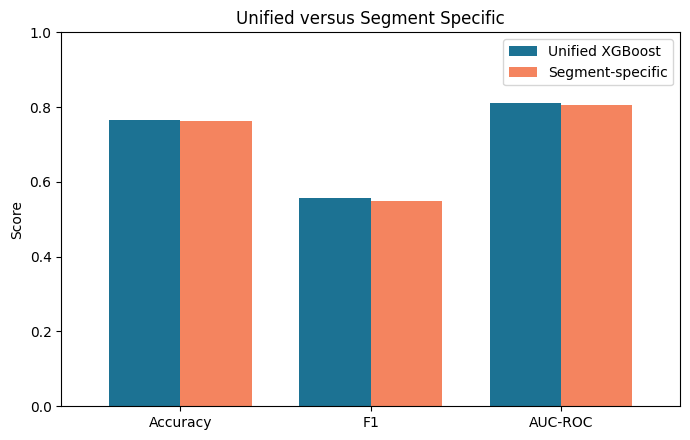

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
comparison.plot(kind='bar', ax=ax, color=['#1C7293', '#F4845F'], width=0.75)
ax.set_ylabel('Score'); ax.set_title('Unified versus Segment Specific')
ax.set_ylim(0, 1); ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../results/figures/comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Like for like comparison inside each segment

This is the comparison that actually answers RQ2 at the segment level. The unified model is evaluated on each segment's own test rows, so both models are scored on exactly the same customers with the same metrics.

Without this step, a segment score would be compared against a score computed over a different population, and any apparent advantage could simply reflect a difference in class balance rather than a difference in model quality.

In [6]:
rows = []
for seg in sorted(seg_test.unique()):
    mask  = (seg_test == seg).values
    y_sub = y_test[mask]

    f1_uni = f1_score(y_sub, unified_preds[mask], zero_division=0)
    f1_seg = f1_score(y_sub, segment_preds[mask], zero_division=0)
    try:
        auc_uni = roc_auc_score(y_sub, unified_probas[mask])
        auc_seg = roc_auc_score(y_sub, segment_probas[mask])
    except ValueError:
        auc_uni = auc_seg = np.nan

    rows.append([seg, mask.sum(), y_sub.mean(),
                 f1_uni, f1_seg, f1_seg - f1_uni,
                 auc_uni, auc_seg, auc_seg - auc_uni])

like_for_like = pd.DataFrame(rows, columns=[
    'Segment', 'n_test', 'ChurnRate',
    'F1_unified', 'F1_segment', 'F1_diff',
    'AUC_unified', 'AUC_segment', 'AUC_diff']).round(3)

print(like_for_like)
print()
print('A positive F1_diff means the segment specific model is better on those customers.')

   Segment  n_test  ChurnRate  F1_unified  F1_segment  F1_diff  AUC_unified  \
0        0     418      0.146       0.267       0.235   -0.031        0.712   
1        1     305      0.236       0.500       0.465   -0.035        0.792   
2        2     478      0.494       0.638       0.645    0.007        0.696   
3        3     206      0.024       0.333       0.222   -0.111        0.797   

   AUC_segment  AUC_diff  
0        0.700    -0.011  
1        0.779    -0.013  
2        0.706     0.010  
3        0.663    -0.134  

A positive F1_diff means the segment specific model is better on those customers.


## 5. Interpret honestly

Look at the sign of F1_diff and AUC_diff in each row. If the unified model wins everywhere, then splitting the data imposed a cost that specialisation did not recover, and the report should say so.

Also note how the segment with the highest churn rate produces a high F1 for both models. That is a property of the class balance in that subgroup, not evidence that specialisation helped. Reporting this distinction clearly is what earns marks in the discussion.

## 6. Save

In [7]:
comparison.to_csv('../results/tables/comparison_unified_vs_segment.csv')
like_for_like.to_csv('../results/tables/like_for_like_comparison.csv', index=False)
print('Saved: comparison_unified_vs_segment.csv, like_for_like_comparison.csv, comparison.png')

Saved: comparison_unified_vs_segment.csv, like_for_like_comparison.csv, comparison.png
